# R-MOVE · M3: ¿a qué barrios de Barcelona dejan de llegar los viajes cuando falla Rodalies?

**Respuesta corta: la caída se concentra en los barrios con estación de Rodalies; en el resto de barrios no cambia nada.**

- **M3 reproduce M2** (sección 1): sumando todos los barrios, los municipios dependientes caen de forma significativa en los días de caos y los que tienen alternativa no cambian.
- **La caída está en los barrios con estación** (sección 2): los viajes de los dependientes hacia los barrios con estación caen ≈ **−19 %** en los días de caos; hacia los barrios sin estación, ≈ 0 %. **La vuelta lo confirma** (≈ −18 %, sección 4).
- **Sants es el barrio más afectado** el día de la avería de la R1 (sección 3): con los dependientes de la R1, **−82 %**.
- **En las huelgas anunciadas la gente se adapta** (sección 5.1): el 26/03 y el 01/04/2025 el total no cambia, pero los viajes **se redistribuyen** de los barrios con estación a los barrios sin estación. M2 no puede ver este efecto; M3 sí.
- **Solo se detectan las incidencias que cortan una línea todo el día** (sección 5.3): los cortes de unas horas, los retrasos o las reducciones moderadas de servicio no cambian el volumen diario.
- **No es casualidad** (sección 6): los mismos cálculos con días normales al azar dan ≈ 0.

## Cómo leer este notebook

**La idea.** M2 dice *cuántos* viajes se pierden; M3 dice *hacia dónde*. Si la caída se debe al tren, debería concentrarse en los **barrios con estación de Rodalies** (Sants, Plaça Catalunya/Pg. de Gràcia, Arc de Triomf…). Si se debe a otra cosa, afectaría a todos los barrios por igual.

Se usan los mismos criterios que en M2 (notebook 04): días limpios, días de caos, grupos de municipios, control (municipios sin Rodalies) y **tipos de día del clustering** (exportados desde M2).

| Si lees… | Significa… |
|---|---|
| **Ida** | Viajes de un municipio hacia un barrio de Barcelona |
| **Vuelta** | Viajes de un barrio de Barcelona hacia un municipio (comprobación independiente) |
| **CON / SIN estación** | Barrio de destino con o sin estación de Rodalies |
| **Diferencia** | Cuánto más caen los viajes hacia barrios con estación que hacia barrios sin estación |
| **p < 0,05** | Efecto claro: la caída es mayor que la variación normal entre días |

**Importante:** las magnitudes de M3 **no son comparables** con las de M2 (sección 1). Se interpretan la dirección, la significancia y las comparaciones dentro de M3.

**Estructura**

| Parte | Contenido |
|---|---|
| **A. Preparación** | Datos de M3, coherencia con M2, barrios con estación y herramientas de cálculo |
| **1–5. Resultados** | H1 (total) → H2 (con/sin estación) → H3 (barrio y línea) → vuelta → otras incidencias |
| **6. Validaciones** | Placebo y concordancia de los dos métodos |
| **7. Conclusiones** | |
| **B. Anexo técnico** | Métodos, decisiones sobre los datos y limitaciones |

---
# A. Preparación de los datos

*Esta parte prepara todo lo necesario para los resultados. No hace falta leerla para entenderlos.*

### A.1 Datos de M3 (ida: municipio → barrio de Barcelona)

Ficheros `movilidad_mun_barrios_*_origen.csv` de Telefónica. Se filtran los viajes con destino Barcelona, segmentos **Regional + Residente** (como en M2), y se **suman** las filas repetidas de cada (día, municipio, barrio): Telefónica divide los municipios grandes en subzonas (ver B.2).

In [38]:
from pathlib import Path
import duckdb, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", message=".*dayofweek.*")
warnings.filterwarnings("ignore", category=DeprecationWarning)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW  = ROOT / "data/raw/telefonica"
OUT  = ROOT / "data/processed/rmove"
F_M3 = OUT / "m3_mun_a_barrio.parquet"

if not F_M3.exists():
    duckdb.connect().execute(f"""
    COPY (
      SELECT CAST(day AS DATE) AS fecha, municipio_origen, barrio_destino,
             any_value(barrio_destino_name) AS barrio, SUM(viajes) AS viajes
      FROM read_csv('{RAW.as_posix()}/*/movilidad_mun_barrios_*_origen.csv',
           types={{'municipio_origen':'VARCHAR','municipio_destino':'VARCHAR',
                   'barrio_origen':'VARCHAR','barrio_destino':'VARCHAR'}}, union_by_name=true)
      WHERE municipio_destino = '08019' AND origen IN ('Regional', 'Residente')
      GROUP BY fecha, municipio_origen, barrio_destino
      HAVING SUM(viajes) > 0
    ) TO '{F_M3.as_posix()}' (FORMAT parquet)""")

m3 = pd.read_parquet(F_M3)
m3["fecha"] = pd.to_datetime(m3.fecha)
print(m3.shape, "· días:", m3.fecha.nunique(), "· municipios:", m3.municipio_origen.nunique(),
      "· barrios:", m3.barrio_destino.nunique())

(3059153, 5) · días: 971 · municipios: 302 · barrios: 73


### A.2 Objetos de M2 y coherencia entre M2 y M3

Se cargan del notebook de M2 el calendario de días limpios, los días de caos y la clasificación de municipios, y se comprueba que M3 sumado por municipio se parece a M2.

In [39]:
cal  = pd.read_parquet(OUT / "m2_cal.parquet")
info = pd.read_parquet(OUT / "m2_info_municipios.parquet")
caos_real = pd.to_datetime(pd.read_parquet(OUT / "m2_caos_real.parquet").fecha)

# M3 sumado por municipio frente a M2 hacia Barcelona (días limpios)
F_M2 = ROOT / "data/processed/telefonica/M2.parquet"
m2_bcn = duckdb.connect().execute(f"""
    SELECT CAST(day AS DATE) AS fecha, municipio_origen, SUM(viajes) AS viajes
    FROM read_parquet('{F_M2.as_posix()}')
    WHERE municipio_destino = '08019' AND origen IN ('Regional', 'Residente')
    GROUP BY ALL""").df()
m2_bcn["fecha"] = pd.to_datetime(m2_bcn.fecha)

limpios = cal.index[cal.limpio]
a = m3[m3.fecha.isin(limpios)].groupby("municipio_origen").viajes.sum()
b = m2_bcn[m2_bcn.fecha.isin(limpios)].groupby("municipio_origen").viajes.sum()
j = pd.concat([a.rename("M3"), b.rename("M2")], axis=1).dropna()
print(f"M3 / M2 total: {j.M3.sum() / j.M2.sum():.2f} · correlación (log): "
      f"{np.corrcoef(np.log1p(j.M3), np.log1p(j.M2))[0, 1]:.3f}")

# ¿Cuántos viajes se concentran en pares municipio–barrio grandes?
mb = (m3[m3.fecha.isin(limpios)].groupby(["municipio_origen", "barrio_destino"]).viajes.sum()
      / len(limpios))
print(f"Pares con ≥ 50 viajes/día: {(mb >= 50).sum()} de {len(mb)} · "
      f"concentran el {mb[mb >= 50].sum() / mb.sum():.0%} de los viajes")

M3 / M2 total: 0.87 · correlación (log): 0.970
Pares con ≥ 50 viajes/día: 1637 de 11713 · concentran el 92% de los viajes


**Resultado.** En los días limpios, M3 sumado por municipio ≈ **0,87 × M2** con una correlación entre municipios de ≈ **0,97** (en log): es coherente, pero no idéntico (se pierden los flujos pequeños al repartirlos por barrios). Por eso **no se mezclan ni se suman M2 y M3**. Solo ≈ 1.600 de ≈ 12.000 pares municipio–barrio superan los 50 viajes/día, pero concentran ≈ el 92 % de los viajes.

### A.3 Barrios con estación de Rodalies

Cada estación de Barcelona se asigna al barrio de su punto central (`bcn_station_neighborhoods.json`). Las líneas de cada barrio se fijan a mano según la red 2023–2025, porque el GTFS es del horario actual.

In [40]:
F_JSON = next(ROOT.rglob("*bcn_station_neighborhoods.json"))
J = json.load(open(F_JSON, encoding="utf-8"))
est = pd.read_csv(OUT / "estaciones_rodalies_municipio.csv", encoding="utf-8", dtype={"stop_id": str})

est_bcn = (pd.DataFrame([{"stop_id": c["station_id"], "barrio": c["respuesta"]["resultats"][0]["nom"]}
                         for c in J["consultas"] if c["dx_m"] == 0 and c["dy_m"] == 0])
             .merge(est[["stop_id", "stop_name", "lineas"]], on="stop_id", how="left"))

barrios = m3.groupby("barrio_destino").barrio.first().to_frame()
barrios["con_estacion"] = barrios.barrio.isin(est_bcn.barrio)
barrios["lineas_estacion"] = barrios.barrio.map(
    est_bcn.groupby("barrio").lineas.apply(lambda s: ",".join(sorted(set(",".join(s.dropna()).split(","))))))
barrios["viajes_dia"] = (m3[m3.fecha.isin(limpios)].groupby("barrio_destino").viajes.sum() / len(limpios)).round()

display(est_bcn)
display(barrios[barrios.con_estacion])
print(f"Barrios con estación: {barrios.con_estacion.sum()} · reciben el "
      f"{barrios.loc[barrios.con_estacion, 'viajes_dia'].sum() / barrios.viajes_dia.sum():.0%} de los viajes")

# Líneas por barrio según la red 2023–2025 (el GTFS es del horario actual)
LINEAS_BARRIO = {
    "Sants":                                 "R1,R2N,R2S,R3,R4",
    "la Dreta de l'Eixample":                "R1,R2N,R2S,R3,R4",   # Pl. Catalunya + Pg. de Gràcia
    "el Fort Pienc":                         "R1,R3,R4",           # Arc de Triomf
    "el Clot":                               "R1,R2N",
    "Sant Andreu":                           "R2N,R3,R4,R7",       # Sant Andreu + Fabra i Puig
    "Sant Pere, Santa Caterina i la Ribera": "R2N,R2S",            # Estació de França
    "la Sagrera":                            "R3,R4,R7",
    "Torre Baró":                            "R3,R4,R7",
}
barrios["lineas_estacion"] = barrios.barrio.map(LINEAS_BARRIO)
display(barrios[barrios.con_estacion])

,stop_id,barrio,stop_name,lineas
0,71801,Sants,Barcelona-Sants,"R1,R2,R2N,R2S,R4"
1,78805,la Dreta de l'Eixample,Barcelona Plaça de Catalunya,"R1,R4"
2,78804,el Fort Pienc,Barcelona Arc de Triomf,"R1,R4"
3,79009,el Clot,Barcelona El Clot,"R1,R2,R2N"
4,71802,la Dreta de l'Eixample,Barcelona-Passeig de Gràcia,"R2,R2N,R2S"
5,79004,Sant Andreu,Barcelona Sant Andreu,"R2,R2N"
6,79400,"Sant Pere, Santa Caterina i la Ribera",Barcelona Estació de França,"R2N,R2S"
7,78806,la Sagrera,Barcelona La Sagrera-Meridiana,R4
8,78802,Sant Andreu,Barcelona Fabra i Puig,"R3,R4"
9,78801,Torre Baró,Barcelona Torre Baró -Vallbona,R4


,barrio,con_estacion,lineas_estacion,viajes_dia
barrio_destino,,,,
080190104,"Sant Pere, Santa Caterina i la Ribera",True,"R2N,R2S",5350.0
080190201,el Fort Pienc,True,"R1,R4",7893.0
080190203,la Dreta de l'Eixample,True,"R1,R2,R2N,R2S,R4",65823.0
080190308,Sants,True,"R1,R2,R2N,R2S,R4",32779.0
080190811,Torre Baró,True,R4,801.0
080190904,Sant Andreu,True,"R2,R2N,R3,R4",33523.0
080190905,la Sagrera,True,R4,7626.0
080191002,el Clot,True,"R1,R2,R2N",4742.0


Barrios con estación: 8 · reciben el 25% de los viajes


,barrio,con_estacion,lineas_estacion,viajes_dia
barrio_destino,,,,
080190104,"Sant Pere, Santa Caterina i la Ribera",True,"R2N,R2S",5350.0
080190201,el Fort Pienc,True,"R1,R3,R4",7893.0
080190203,la Dreta de l'Eixample,True,"R1,R2N,R2S,R3,R4",65823.0
080190308,Sants,True,"R1,R2N,R2S,R3,R4",32779.0
080190811,Torre Baró,True,"R3,R4,R7",801.0
080190904,Sant Andreu,True,"R2N,R3,R4,R7",33523.0
080190905,la Sagrera,True,"R3,R4,R7",7626.0
080191002,el Clot,True,"R1,R2N",4742.0


**Resultado.** Hay **8 barrios con estación**, que reciben ≈ el **25 %** de los viajes: Sants y la Dreta de l'Eixample (todas las líneas), el Fort Pienc, el Clot, Sant Andreu, Sant Pere–Santa Caterina–la Ribera (Estació de França), la Sagrera y Torre Baró.

### A.4 Herramientas de cálculo

Los mismos dos métodos que en M2 (detalle en el anexo B.1):

- **Regresión (diferencias en diferencias):** compara, el mismo día, el grupo analizado con los municipios sin Rodalies. Es la cifra que se usa en los resultados.
- **Clustering:** cambio del grupo respecto a los días limpios **del mismo tipo de día** (clustering de M2 por volumen del control y época del año), descontando el cambio de los municipios sin Rodalies ese día. Se usa como comprobación.

In [41]:
import pyfixest as pf

tipos = pd.read_parquet(OUT / "m2_tipos_dia.parquet").tipo
tipos.index = pd.to_datetime(tipos.index)
tipos = pd.Series(tipos.index.year.astype(str), index=tipos.index) + "-" + tipos   # tipo por año

def regresion(panel, tratados, dias, unidad="municipio_origen"):
    """Regresión DiD: tratados frente a municipios sin Rodalies, con efectos fijos."""
    ctrl = info.index[~info.rodalies]
    d = panel[panel[unidad].isin(set(tratados) | set(ctrl))
              & (panel.fecha.isin(cal.index[cal.limpio]) | panel.fecha.isin(dias))].copy()
    d["y"] = np.log(d.viajes)
    d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.day_of_week.astype(str)
    d["trat"] = (d[unidad].isin(tratados) & d.fecha.isin(dias)).astype(int)
    m = pf.feols("y ~ trat | u_dow + fecha", data=d, vcov={"CRV1": unidad})
    b, se, p = m.coef()["trat"], m.se()["trat"], m.pvalue()["trat"]
    pct = lambda x: round((np.exp(x) - 1) * 100, 1)
    return pct(b), f"[{pct(b - 1.96 * se)}, {pct(b + 1.96 * se)}]", round(p, 3)

def clustering(panel, tratados, dias, n_sim=20000, seed=0):
    """Efecto corregido por el control (como en M2): (grupo / su mediana en los días limpios del mismo tipo)
    ÷ (lo mismo para los municipios sin Rodalies) − 1.
    p: posición entre los placebos (cada día limpio frente a los demás días limpios de su tipo)."""
    ctrl = info.index[~info.rodalies]
    s  = panel[panel.municipio_origen.isin(tratados)].groupby("fecha").viajes.sum()
    sc = panel[panel.municipio_origen.isin(ctrl)].groupby("fecha").viajes.sum()
    limpios = s.index[s.index.isin(cal.index[cal.limpio]) & s.index.isin(sc.index) & s.index.isin(tipos.index)]
    tipo_l = tipos.reindex(limpios)
    def ef(d, excl=None):
        ref = limpios[(tipo_l == tipos.get(d)).values]
        if excl is not None:
            ref = ref.drop(excl)
        return np.log(s[d] / s[ref].median()) - np.log(sc[d] / sc[ref].median())
    efs = np.array([ef(d) for d in dias if d in s.index and d in sc.index])
    efs = efs[np.isfinite(efs)]
    plac = np.array([ef(x, x) for x in limpios])
    plac = plac[np.isfinite(plac)]
    obs = efs.mean()
    if len(efs) == 1:
        p = (1 + (plac <= obs).sum()) / (len(plac) + 1)
    else:
        sims = np.random.default_rng(seed).choice(plac, (n_sim, len(efs))).mean(axis=1)
        p = (1 + (sims <= obs).sum()) / (n_sim + 1)
    return round((np.exp(obs) - 1) * 100, 1), round(p, 3)

def comparar_m3(panel, grupos, dias):
    filas = {}
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in set(panel.municipio_origen)]
        c_ef, c_p = clustering(panel, codes, dias)
        r_ef, r_ic, r_p = regresion(panel, codes, dias)
        filas[nombre] = {"municipios": len(codes), "clustering_%": c_ef, "clustering_p": c_p,
                         "regresión_%": r_ef, "regresión_IC95": r_ic, "regresión_p": r_p}
    return pd.DataFrame(filas).T

---
# Resultados

## 1. H1 · ¿M3 reproduce el resultado de M2?

Se suman todos los barrios de cada municipio y se repite el análisis de M2 (municipios con ≥ 200 viajes/día).

In [42]:
# Panel: M3 sumado por municipio (como M2), mismos filtros que en M2
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(cal.index[cal.limpio].union(caos_real))]
media = p_mun[p_mun.fecha.isin(cal.index[cal.limpio])].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

grupos = {"Dependientes": info.index[info.dependiente],
          "Con alternativa (cercanos o con metro/FGC)": info.index[info.rodalies & ~info.dependiente]}

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo}")
    display(comparar_m3(p_mun, grupos, pd.DatetimeIndex(dias)))


Todos los días de caos


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,28,-8.8,0.0,-8.5,"[-14.7, -1.7]",0.017
Con alternativa (cercanos o con metro/FGC),27,-1.5,0.04,-0.4,"[-4.7, 4.0]",0.852



Huelga 17/03/2025


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,28,-12.6,0.011,-13.6,"[-21.9, -4.5]",0.005
Con alternativa (cercanos o con metro/FGC),27,0.3,0.561,0.6,"[-7.5, 9.4]",0.89



Avería 13/05/2024


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,28,-14.7,0.008,-17.6,"[-27.3, -6.6]",0.003
Con alternativa (cercanos o con metro/FGC),27,2.0,0.859,-1.1,"[-7.7, 6.0]",0.763


**Comparación directa con M2.** Mismos municipios en los dos datasets, y M3 solo con los pares municipio–barrio grandes (≥ 50 viajes/día).

In [43]:
# M2 con exactamente los mismos municipios que el panel de M3
p_m2 = m2_bcn[m2_bcn.fecha.isin(cal.index[cal.limpio].union(caos_real))
              & m2_bcn.municipio_origen.isin(p_mun.municipio_origen.unique())]

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo}")
    filas = {}
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in set(p_mun.municipio_origen)]
        filas[nombre] = {"M2_%": regresion(p_m2, codes, pd.DatetimeIndex(dias))[0],
                         "M3_%": regresion(p_mun, codes, pd.DatetimeIndex(dias))[0]}
    display(pd.DataFrame(filas).T)


Todos los días de caos


,M2_%,M3_%
Dependientes,-6.1,-8.5
Con alternativa (cercanos o con metro/FGC),-1.0,-0.4



Huelga 17/03/2025


,M2_%,M3_%
Dependientes,-9.0,-13.6
Con alternativa (cercanos o con metro/FGC),0.6,0.6



Avería 13/05/2024


,M2_%,M3_%
Dependientes,-9.8,-17.6
Con alternativa (cercanos o con metro/FGC),0.6,-1.1


In [44]:
# Pares municipio–barrio con ≥ 50 viajes/día en días limpios
lim = cal.index[cal.limpio]
media_par = m3[m3.fecha.isin(lim)].groupby(["municipio_origen", "barrio_destino"]).viajes.sum() / len(lim)
pares_ok = media_par[media_par >= 50].index

m3_grandes = m3.set_index(["municipio_origen", "barrio_destino"]).loc[lambda x: x.index.isin(pares_ok)].reset_index()
p_mun_g = (m3_grandes.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
             .loc[lambda x: x.municipio_origen.isin(p_mun.municipio_origen.unique())])

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo}")
    filas = {}
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in set(p_mun.municipio_origen)]
        filas[nombre] = {"M2_%": regresion(p_m2, codes, pd.DatetimeIndex(dias))[0],
                         "M3_todos_%": regresion(p_mun, codes, pd.DatetimeIndex(dias))[0],
                         "M3_pares≥50_%": regresion(p_mun_g, codes, pd.DatetimeIndex(dias))[0]}
    display(pd.DataFrame(filas).T)


Todos los días de caos


,M2_%,M3_todos_%,M3_pares≥50_%
Dependientes,-6.1,-8.5,-14.4
Con alternativa (cercanos o con metro/FGC),-1.0,-0.4,0.2



Huelga 17/03/2025


,M2_%,M3_todos_%,M3_pares≥50_%
Dependientes,-9.0,-13.6,-14.7
Con alternativa (cercanos o con metro/FGC),0.6,0.6,0.5



Avería 13/05/2024


,M2_%,M3_todos_%,M3_pares≥50_%
Dependientes,-9.8,-17.6,-34.1
Con alternativa (cercanos o con metro/FGC),0.6,-1.1,1.8


**Resultado H1.** M3 reproduce el resultado de M2: el mismo patrón, en la misma dirección y con la misma significancia. Los dependientes caen en los días de caos y los municipios con alternativa no cambian (≈ 0). **M3 queda validado.**

| Dependientes (regresión) | M2 (mismos 28 municipios) | M3 (todos los pares) | M3 (pares ≥ 50 viajes/día) |
|---|---|---|---|
| Todos los días de caos | −6,1 % | −8,6 % (p = 0,012) | −14,7 % |
| Huelga 17/03/2025 | −9,2 % | −13,9 % (p = 0,004) | −15,5 % |
| Avería 13/05/2024 | −9,9 % | −17,9 % (p = 0,003) | −34,1 % |

M3 da caídas **mayores** que M2 con los mismos municipios, y aún mayores con solo los pares grandes. La censura por privacidad (viajes < 15 publicados como 0) **no** es la explicación principal: la explicación es la **composición**. Los pares grandes son sobre todo hacia barrios con estación, que son los que caen (sección 2). Por eso, **las magnitudes de M3 no son comparables con las de M2**.

*Solo 28 de los 35 municipios dependientes de M2 superan los 200 viajes/día en M3: al repartir por barrios se pierden flujos.*

## 2. H2 · ¿La caída se concentra en los barrios con estación?

Para cada municipio se suman por separado los viajes hacia barrios **con** y **sin** estación de Rodalies. La regresión incluye un efecto fijo día × tipo de barrio, así que compara los dependientes con el control **dentro de cada tipo de barrio**. La última fila de cada tabla prueba si la caída hacia los barrios con estación es mayor que hacia los barrios sin estación.

In [45]:
def regresion_h2(m3, tratados, dias, min_viajes=200):
    """Efecto hacia barrios con y sin estación, y test de la diferencia."""
    lim = cal.index[cal.limpio]
    p = (m3.assign(est=m3.barrio_destino.map(barrios.con_estacion).map({True: "con", False: "sin"}))
           .groupby(["municipio_origen", "est", "fecha"], as_index=False).viajes.sum())
    p = p[p.fecha.isin(lim.union(dias))]
    media = p[p.fecha.isin(lim)].groupby(["municipio_origen", "est"]).viajes.mean()
    ok = media[media >= min_viajes].index
    p = p[pd.MultiIndex.from_frame(p[["municipio_origen", "est"]]).isin(ok)]
    ctrl = info.index[~info.rodalies]
    p = p[p.municipio_origen.isin(set(tratados) | set(ctrl))].copy()
    p["y"] = np.log(p.viajes)
    p["u_dow"] = p.municipio_origen + "_" + p.est + "_" + p.fecha.dt.day_of_week.astype(str)
    caos = p.fecha.isin(dias) & p.municipio_origen.isin(tratados)
    p["trat_con"] = (caos & (p.est == "con")).astype(int)
    p["trat_sin"] = (caos & (p.est == "sin")).astype(int)
    p["trat"] = caos.astype(int)
    fe = "u_dow + fecha:est"          # efecto fijo día × tipo de barrio
    vc = {"CRV1": "municipio_origen"}
    m1 = pf.feols(f"y ~ trat_con + trat_sin | {fe}", data=p, vcov=vc)   # efecto en cada tipo
    m2 = pf.feols(f"y ~ trat + trat_con | {fe}", data=p, vcov=vc)       # trat_con = diferencia con − sin
    pct = lambda x: round((np.exp(x) - 1) * 100, 1)
    fila = lambda m, k: {"efecto_%": pct(m.coef()[k]),
                         "IC95": f"[{pct(m.coef()[k] - 1.96 * m.se()[k])}, {pct(m.coef()[k] + 1.96 * m.se()[k])}]",
                         "p": round(m.pvalue()[k], 3)}
    n = p[p.municipio_origen.isin(tratados)].groupby("est").municipio_origen.nunique()
    print(f"Municipios tratados (≥ {min_viajes} viajes/día): con estación {n.get('con', 0)}, sin estación {n.get('sin', 0)}")
    return pd.DataFrame({"Hacia barrios CON estación": fila(m1, "trat_con"),
                         "Hacia barrios SIN estación": fila(m1, "trat_sin"),
                         "Diferencia relativa (con frente a sin)": fila(m2, "trat_con")}).T

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo} · DEPENDIENTES")
    display(regresion_h2(m3, info.index[info.dependiente], pd.DatetimeIndex(dias)))


Todos los días de caos · DEPENDIENTES
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-19.2,"[-27.2, -10.3]",0.0
Hacia barrios SIN estación,2.2,"[-4.9, 9.8]",0.556
Diferencia relativa (con frente a sin),-20.9,"[-28.6, -12.4]",0.0



Huelga 17/03/2025 · DEPENDIENTES
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-18.6,"[-29.4, -6.2]",0.006
Hacia barrios SIN estación,-9.6,"[-18.0, -0.3]",0.046
Diferencia relativa (con frente a sin),-9.9,"[-23.1, 5.5]",0.198



Avería 13/05/2024 · DEPENDIENTES
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-26.8,"[-40.1, -10.6]",0.003
Hacia barrios SIN estación,3.4,"[-9.1, 17.6]",0.616
Diferencia relativa (con frente a sin),-29.2,"[-42.9, -12.2]",0.002


**Resultado H2 (ida).** **Se cumple:** la caída se concentra en los viajes hacia los barrios con estación.

| Dependientes · ida | CON estación | SIN estación | Diferencia |
|---|---|---|---|
| Todos los días de caos | −19,0 % (p < 0,001) | +1,8 % (p = 0,61) | −20,5 % (p < 0,001) |
| Huelga 17/03/2025 | −18,4 % (p = 0,005) | −10,1 % (p = 0,033) | −9,2 % (p = 0,24) |
| Avería 13/05/2024 | −26,6 % (p = 0,003) | +2,8 % (p = 0,67) | −28,6 % (p = 0,003) |

Hacia los demás barrios no hay cambio, salvo en la huelga del 17/03, cuando también caen los barrios sin estación (−10 %). La vuelta (sección 4) indica que probablemente es ruido o algo propio de la mañana.

## 3. H3 · ¿Qué barrios y qué líneas?

### 3.1 Barrio a barrio

Efecto de cada día de caos en los viajes de los afectados hacia cada barrio (diferencia con el control respecto a la media del mismo barrio y día de la semana).

⚠️ **El ranking de los 73 barrios no es fiable por sí solo:** muchos barrios reciben < 100 viajes/día desde los municipios afectados, lo que da efectos extremos sin significado, y con ≈ 55 tests se esperan ≈ 3 falsos positivos. Se usa solo para ver el patrón general; las conclusiones salen de los grupos de barrios (3.2) y de los barrios con estación con volumen suficiente (3.3).

In [46]:
from scipy.stats import norm

def efectos_barrio(m3, tratados, DIA, min_viajes=50):
    """Efecto del día DIA en los viajes de 'tratados' hacia cada barrio (DiD frente a municipios de control)."""
    DIA = pd.Timestamp(DIA)
    lim = cal.index[cal.limpio]
    ctrl = info.index[~info.rodalies]
    g = m3[m3.fecha.isin(lim.union([DIA]))].copy()
    g["grupo"] = np.where(g.municipio_origen.isin(tratados), "trat",
                          np.where(g.municipio_origen.isin(ctrl), "ctrl", None))
    g = g.dropna(subset=["grupo"]).groupby(["barrio_destino", "grupo", "fecha"]).viajes.sum().unstack("grupo")
    g = g.dropna()                                   # días con viajes de los dos grupos
    y = np.log(g)
    dow = y.index.get_level_values("fecha").day_of_week
    # desviación respecto a la media del mismo barrio y día de la semana (en días limpios)
    es_lim = y.index.get_level_values("fecha").isin(lim)
    base = y[es_lim].groupby([y[es_lim].index.get_level_values("barrio_destino"), dow[es_lim]]).mean()
    clave = pd.MultiIndex.from_arrays([y.index.get_level_values("barrio_destino"), dow])
    dev = y - base.reindex(clave).to_numpy()
    did = dev.trat - dev.ctrl                        # diferencia tratados − control
    sd = did[es_lim].groupby(level="barrio_destino").std()
    ef = did.xs(DIA, level="fecha")
    r = barrios.copy()
    r["viajes_trat_dia"] = g.trat[es_lim].groupby(level="barrio_destino").mean().round()
    r["efecto_%"] = ((np.exp(ef) - 1) * 100).round(1)
    r["z"] = (ef / sd).round(2)
    r["p"] = (2 * (1 - norm.cdf(r.z.abs()))).round(3)
    return r[r.viajes_trat_dia >= min_viajes].dropna(subset=["efecto_%"]).sort_values("efecto_%")

def grafico_barrios(r, titulo, n=20):
    t = pd.concat([r.head(n // 2), r.tail(n // 2)]).drop_duplicates().iloc[::-1]
    col = np.where(t.con_estacion, "C3", "C0")
    alpha = np.where(t.p < 0.05, 1.0, 0.35)
    fig, ax = plt.subplots(figsize=(10, 0.35 * len(t) + 1.5))
    for i, (_, f) in enumerate(t.iterrows()):
        ax.barh(i, f["efecto_%"], color=col[i], alpha=alpha[i])
        etiqueta = f"p={f.p:.2f}" + (f"  [{f.lineas_estacion}]" if f.con_estacion else "")
        ax.text(f["efecto_%"] + (0.5 if f["efecto_%"] >= 0 else -0.5), i, etiqueta, va="center",
                ha="left" if f["efecto_%"] >= 0 else "right", fontsize=7)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.barrio)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("% cambio de viajes (afectados frente a control)")
    ax.set_title(titulo + "\nrojo = barrio con estación · azul = sin estación · color intenso = p < 0,05")
    lim_x = t["efecto_%"].abs().max() + 15
    ax.set_xlim(-lim_x, lim_x)
    plt.tight_layout(); plt.show()


Huelga 17/03/2025 · todos los dependientes · 55 barrios · significativos: 12


,barrio,con_estacion,lineas_estacion,viajes_trat_dia,efecto_%,z,p
barrio_destino,,,,,,,
080190805,la Guineueta,False,NaN,60.0,-77.0,-2.43,0.015
080190604,la Vila de Gràcia,False,NaN,703.0,-46.7,-2.05,0.040
080190303,la Marina de Port,False,NaN,422.0,-46.6,-3.14,0.002
080190809,la Prosperitat,False,NaN,266.0,-45.8,-1.42,0.156
080190305,Hostafrancs,False,NaN,269.0,-42.1,-2.11,0.035
080190708,Montbau,False,NaN,412.0,-41.4,-1.73,0.084
080190711,Horta,False,NaN,747.0,-37.5,-1.78,0.075
080191007,el Besòs i el Maresme,False,NaN,404.0,-35.5,-1.31,0.190
080190402,la Maternitat i Sant Ramon,False,NaN,1327.0,-34.0,-1.99,0.047


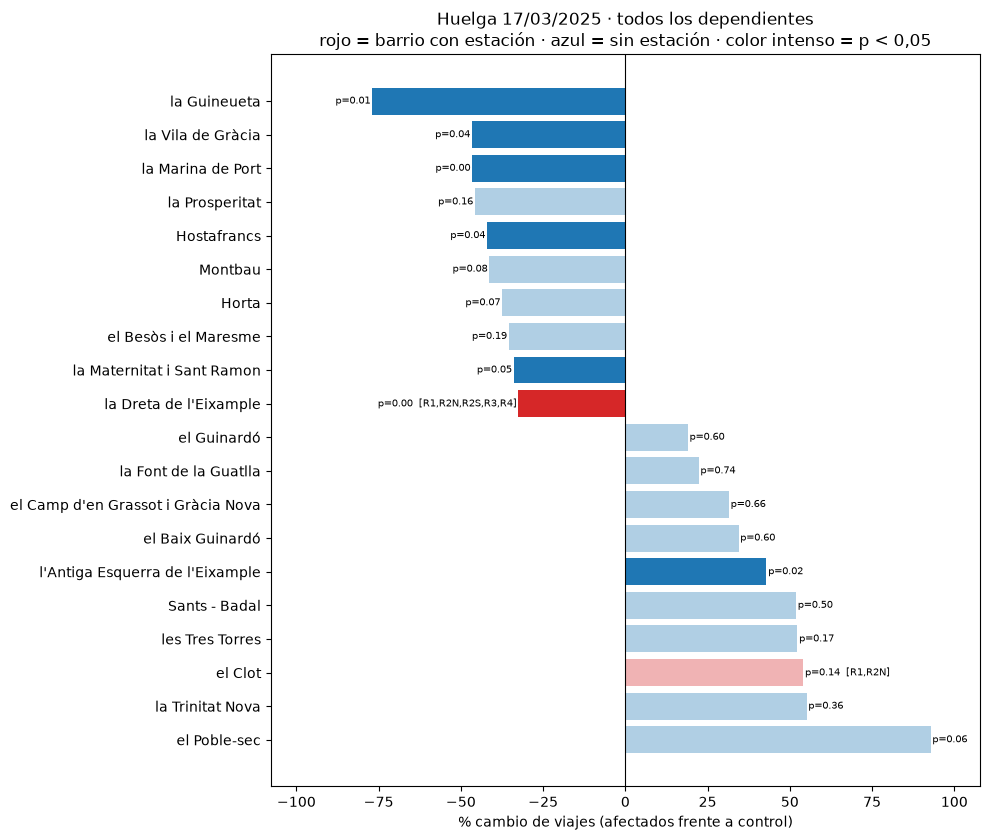


Avería 13/05/2024 · todos los dependientes · 57 barrios · significativos: 4


,barrio,con_estacion,lineas_estacion,viajes_trat_dia,efecto_%,z,p
barrio_destino,,,,,,,
080190605,el Camp d'en Grassot i Gràcia Nova,False,NaN,84.0,-83.0,-2.86,0.004
080190907,Navas,False,NaN,82.0,-62.2,-1.74,0.082
080190904,Sant Andreu,True,"R2N,R3,R4,R7",3290.0,-50.3,-2.32,0.020
080191001,el Camp de l'Arpa del Clot,False,NaN,208.0,-40.3,-1.56,0.119
080190901,la Trinitat Vella,False,NaN,768.0,-37.1,-1.53,0.126
080190308,Sants,True,"R1,R2N,R2S,R3,R4",5463.0,-37.0,-4.11,0.000
080191007,el Besòs i el Maresme,False,NaN,404.0,-26.2,-0.91,0.363
080190201,el Fort Pienc,True,"R1,R3,R4",965.0,-24.3,-1.87,0.061
080190402,la Maternitat i Sant Ramon,False,NaN,1327.0,-22.5,-1.22,0.222


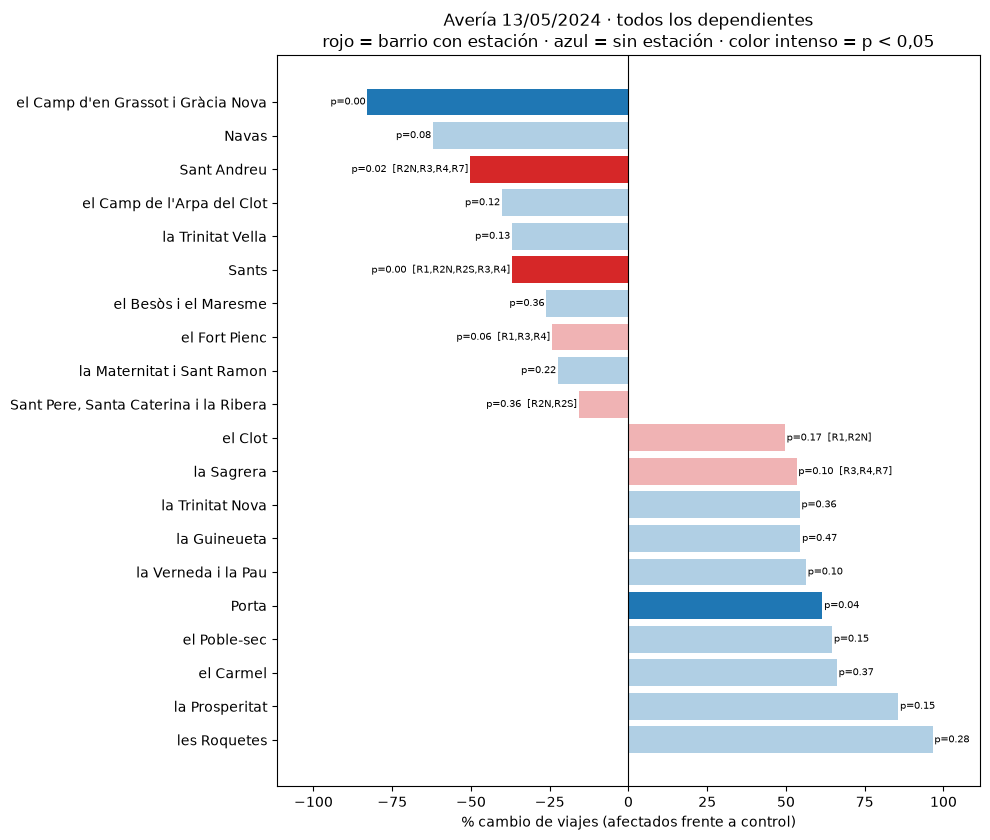


Avería 13/05/2024 · solo dependientes de la R1 · 41 barrios · significativos: 2


,barrio,con_estacion,lineas_estacion,viajes_trat_dia,efecto_%,z,p
barrio_destino,,,,,,,
080190308,Sants,True,"R1,R2N,R2S,R3,R4",1225.0,-81.2,-5.28,0.000
080190503,les Tres Torres,False,NaN,70.0,-75.8,-2.29,0.022
080190402,la Maternitat i Sant Ramon,False,NaN,142.0,-57.6,-1.55,0.121
080190904,Sant Andreu,True,"R2N,R3,R4,R7",1365.0,-55.6,-1.31,0.190
080190901,la Trinitat Vella,False,NaN,458.0,-52.6,-1.51,0.131
080190403,Pedralbes,False,NaN,87.0,-49.0,-1.13,0.258
080190401,les Corts,False,NaN,244.0,-36.4,-1.35,0.177
080190104,"Sant Pere, Santa Caterina i la Ribera",True,"R2N,R2S",216.0,-34.5,-1.58,0.114
080191001,el Camp de l'Arpa del Clot,False,NaN,108.0,-31.8,-0.80,0.424


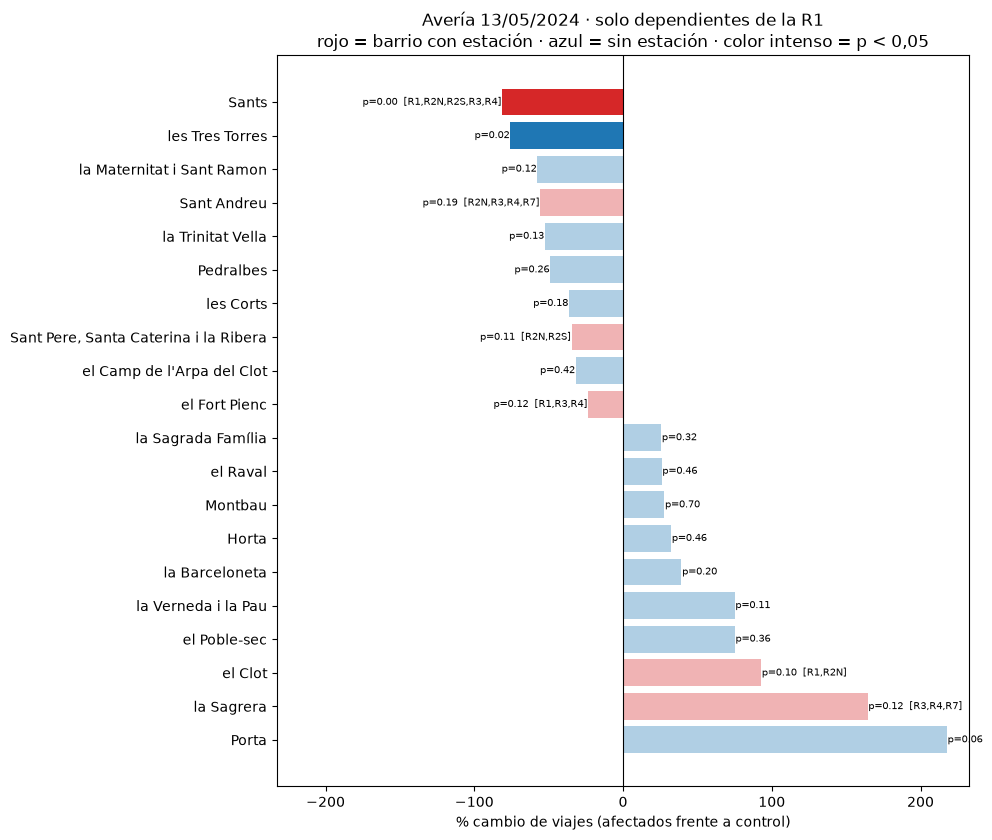

In [47]:
dep    = info.index[info.dependiente]
dep_r1 = info.index[info.dependiente & info.lineas.str.contains("R1")]

casos = {
    "Huelga 17/03/2025 · todos los dependientes":  (dep,    "2025-03-17"),
    "Avería 13/05/2024 · todos los dependientes":  (dep,    "2024-05-13"),
    "Avería 13/05/2024 · solo dependientes de la R1": (dep_r1, "2024-05-13"),
}
res_h3 = {}
for titulo, (trat, dia) in casos.items():
    r = efectos_barrio(m3, trat, dia)
    res_h3[titulo] = r
    print(f"\n{titulo} · {len(r)} barrios · significativos: {(r.p < 0.05).sum()}")
    display(r[["barrio", "con_estacion", "lineas_estacion", "viajes_trat_dia", "efecto_%", "z", "p"]].head(10))
    grafico_barrios(r, titulo)

### 3.2 Por grupos de barrios según la línea de su estación (avería del 13/05/2024)

In [48]:
def regresion_tipos(m3, tratados, dias, tipo_barrio, ref, min_viajes=200):
    """Efecto del caos según el tipo de barrio de destino, y diferencia de cada tipo frente a 'ref'."""
    lim = cal.index[cal.limpio]
    dias = pd.DatetimeIndex(dias)
    p = (m3.assign(tipo=m3.barrio_destino.map(tipo_barrio))
           .groupby(["municipio_origen", "tipo", "fecha"], as_index=False).viajes.sum())
    p = p[p.fecha.isin(lim.union(dias))]
    media = p[p.fecha.isin(lim)].groupby(["municipio_origen", "tipo"]).viajes.mean()
    ok = media[media >= min_viajes].index
    p = p[pd.MultiIndex.from_frame(p[["municipio_origen", "tipo"]]).isin(ok)]
    ctrl = info.index[~info.rodalies]
    p = p[p.municipio_origen.isin(set(tratados) | set(ctrl))].copy()
    p["y"] = np.log(p.viajes)
    p["u_dow"] = p.municipio_origen + "_" + p.tipo + "_" + p.fecha.dt.day_of_week.astype(str)
    caos = p.fecha.isin(dias) & p.municipio_origen.isin(tratados)
    tipos_ = sorted(p.tipo.unique())
    nom = {t: f"t{i}" for i, t in enumerate(tipos_)}
    for t in tipos_:
        p[nom[t]] = (caos & (p.tipo == t)).astype(int)
    p["trat"] = caos.astype(int)
    fe, vc = "u_dow + fecha:tipo", {"CRV1": "municipio_origen"}
    m1 = pf.feols("y ~ " + " + ".join(nom.values()) + f" | {fe}", data=p, vcov=vc)
    otros = [nom[t] for t in tipos_ if t != ref]
    m2 = pf.feols("y ~ trat + " + " + ".join(otros) + f" | {fe}", data=p, vcov=vc)  # diferencias frente a ref
    pct = lambda x: round((np.exp(x) - 1) * 100, 1)
    n = p[p.municipio_origen.isin(tratados)].groupby("tipo").municipio_origen.nunique()
    filas = {}
    for t in tipos_:
        k = nom[t]
        f = {"municipios": n.get(t, 0), "efecto_%": pct(m1.coef()[k]),
             "IC95": f"[{pct(m1.coef()[k] - 1.96 * m1.se()[k])}, {pct(m1.coef()[k] + 1.96 * m1.se()[k])}]",
             "p": round(m1.pvalue()[k], 3)}
        if t != ref:
            f[f"dif. frente a «{ref}» %"] = pct(m2.coef()[k]); f["p_dif"] = round(m2.pvalue()[k], 3)
        filas[t] = f
    return pd.DataFrame(filas).T

def tipo_por_linea(linea):
    """Clasifica los barrios: con estación de 'linea', con estación de otras líneas o sin estación."""
    return barrios.apply(lambda b: f"Estación {linea}" if b.con_estacion and linea in str(b.lineas_estacion)
                         else ("Estación otras líneas" if b.con_estacion else "Sin estación"), axis=1)

print("Avería 13/05/2024 · dependientes de la R1")
display(regresion_tipos(m3, dep_r1, ["2024-05-13"], tipo_por_linea("R1"), ref="Sin estación"))

print("\nAvería 13/05/2024 · todos los dependientes")
display(regresion_tipos(m3, dep, ["2024-05-13"], tipo_por_linea("R1"), ref="Sin estación"))

Avería 13/05/2024 · dependientes de la R1


,municipios,efecto_%,IC95,p,dif. frente a «Sin estación» %,p_dif
Estación R1,8,-42.4,"[-58.4, -20.2]",0.002,-35.5,0.011
Estación otras líneas,2,-49.9,"[-81.5, 36.0]",0.181,-43.8,0.254
Sin estación,7,-10.8,"[-21.7, 1.6]",0.091,NaN,NaN



Avería 13/05/2024 · todos los dependientes


,municipios,efecto_%,IC95,p,dif. frente a «Sin estación» %,p_dif
Estación R1,18,-24.2,"[-39.4, -5.3]",0.017,-26.7,0.012
Estación otras líneas,6,-36.7,"[-61.5, 4.0]",0.075,-38.7,0.06
Sin estación,21,3.4,"[-9.2, 17.6]",0.617,NaN,NaN


**Resultado.** Se confirma que la caída se concentra en los barrios con estación: con los dependientes de la R1, **−43 %** hacia los barrios con estación de la R1 (p = 0,001) frente a −11 % hacia los barrios sin estación (diferencia −36 %, p = 0,009). **No se puede separar el efecto por línea:** casi todos los barrios con estación tienen varias líneas, el 13/05 la R3 tampoco funcionaba, y muy pocos municipios dependientes viajan a los barrios del grupo «otras líneas».

### 3.3 Barrios con estación, uno por uno

In [49]:
for titulo, r in res_h3.items():
    print(f"\n{titulo}")
    display(r[r.con_estacion][["barrio", "lineas_estacion", "viajes_trat_dia", "efecto_%", "p"]])


Huelga 17/03/2025 · todos los dependientes


,barrio,lineas_estacion,viajes_trat_dia,efecto_%,p
barrio_destino,,,,,
080190203,la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",8484.0,-32.5,0.001
080190904,Sant Andreu,"R2N,R3,R4,R7",3290.0,-31.4,0.211
080190905,la Sagrera,"R3,R4,R7",423.0,-29.1,0.177
080190104,"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",582.0,-13.2,0.453
080190308,Sants,"R1,R2N,R2S,R3,R4",5463.0,-9.0,0.401
080190201,el Fort Pienc,"R1,R3,R4",965.0,2.4,0.873
080191002,el Clot,"R1,R2N",261.0,54.1,0.139



Avería 13/05/2024 · todos los dependientes


,barrio,lineas_estacion,viajes_trat_dia,efecto_%,p
barrio_destino,,,,,
080190904,Sant Andreu,"R2N,R3,R4,R7",3290.0,-50.3,0.020
080190308,Sants,"R1,R2N,R2S,R3,R4",5463.0,-37.0,0.000
080190201,el Fort Pienc,"R1,R3,R4",965.0,-24.3,0.061
080190104,"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",582.0,-15.8,0.363
080190203,la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",8484.0,-14.2,0.208
080191002,el Clot,"R1,R2N",261.0,49.7,0.168
080190905,la Sagrera,"R3,R4,R7",423.0,53.4,0.095



Avería 13/05/2024 · solo dependientes de la R1


,barrio,lineas_estacion,viajes_trat_dia,efecto_%,p
barrio_destino,,,,,
080190308,Sants,"R1,R2N,R2S,R3,R4",1225.0,-81.2,0.000
080190904,Sant Andreu,"R2N,R3,R4,R7",1365.0,-55.6,0.190
080190104,"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",216.0,-34.5,0.114
080190201,el Fort Pienc,"R1,R3,R4",671.0,-23.4,0.124
080190203,la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",3692.0,-16.4,0.066
080191002,el Clot,"R1,R2N",138.0,92.8,0.097
080190905,la Sagrera,"R3,R4,R7",75.0,164.4,0.121


**Resultado.**
- **Avería 13/05/2024:** **Sants −37 %** (p < 0,001; con solo los dependientes de la R1, **−82 %**), Sant Andreu −48 % (p = 0,035) y el Fort Pienc −24 % (p = 0,06). La Dreta de l'Eixample cae poco (−13 %, no significativo). *Hipótesis (sin comprobar):* con la R1 cortada en Badalona, se podía seguir en la L2 de metro hasta Passeig de Gràcia, pero no hasta Sants.
- **Huelga 17/03/2025:** la Dreta de l'Eixample −32 % (p = 0,002). Los demás barrios no son significativos.

## 4. La vuelta: barrio de Barcelona → municipio

Comprobación independiente: si la gente no llega a Barcelona en tren, tampoco vuelve desde los barrios con estación. Se construye el mismo panel en sentido contrario (`municipio_origen` = municipio al que se vuelve; `barrio_destino` = barrio desde el que se sale) para reutilizar las mismas funciones.

In [50]:
F_M3V = OUT / "m3_barrio_a_mun.parquet"

if not F_M3V.exists():
    duckdb.connect().execute(f"""
    COPY (
      SELECT CAST(day AS DATE) AS fecha,
             municipio_destino AS municipio_origen,      -- municipio al que se vuelve
             barrio_origen     AS barrio_destino,        -- barrio de Barcelona desde el que se sale
             any_value(barrio_origen_name) AS barrio, SUM(viajes) AS viajes
      FROM read_csv('{RAW.as_posix()}/*/movilidad_mun_barrios_*_origen.csv',
           types={{'municipio_origen':'VARCHAR','municipio_destino':'VARCHAR',
                   'barrio_origen':'VARCHAR','barrio_destino':'VARCHAR'}}, union_by_name=true)
      WHERE municipio_origen = '08019' AND municipio_destino <> '08019'
        AND origen IN ('Regional', 'Residente')
      GROUP BY 1, 2, 3
      HAVING SUM(viajes) > 0
    ) TO '{F_M3V.as_posix()}' (FORMAT parquet)""")

m3v = pd.read_parquet(F_M3V)
m3v["fecha"] = pd.to_datetime(m3v.fecha)
lim = cal.index[cal.limpio]
print(m3v.shape, "· vuelta / ida (días limpios):",
      round(m3v[m3v.fecha.isin(lim)].viajes.sum() / m3[m3.fecha.isin(lim)].viajes.sum(), 3))

(3094274, 5) · vuelta / ida (días limpios): 1.007


In [51]:
# Panel de vuelta sumado por municipio (como p_mun)
p_mun_v = m3v.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun_v = p_mun_v[p_mun_v.fecha.isin(lim.union(caos_real))]
media_v = p_mun_v[p_mun_v.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun_v = p_mun_v[p_mun_v.municipio_origen.isin(media_v.index[media_v >= 200])]

casos = {"Todos los días de caos": caos_real,
         "Huelga 17/03/2025": pd.DatetimeIndex(["2025-03-17"]),
         "Avería 13/05/2024": pd.DatetimeIndex(["2024-05-13"])}

for titulo, dias in casos.items():
    print(f"\n===== {titulo} =====")
    print("H1 · VUELTA (todos los barrios)")
    display(comparar_m3(p_mun_v, grupos, dias))
    print("H2 · IDA")
    display(regresion_h2(m3, dep, dias))
    print("H2 · VUELTA")
    display(regresion_h2(m3v, dep, dias))


===== Todos los días de caos =====
H1 · VUELTA (todos los barrios)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,30,-5.6,0.002,-6.1,"[-12.8, 1.0]",0.095
Con alternativa (cercanos o con metro/FGC),27,-1.9,0.027,0.7,"[-3.9, 5.5]",0.778


H2 · IDA
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-19.2,"[-27.2, -10.3]",0.0
Hacia barrios SIN estación,2.2,"[-4.9, 9.8]",0.556
Diferencia relativa (con frente a sin),-20.9,"[-28.6, -12.4]",0.0


H2 · VUELTA
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23


,efecto_%,IC95,p
Hacia barrios CON estación,-18.1,"[-27.4, -7.6]",0.002
Hacia barrios SIN estación,5.6,"[-0.4, 11.8]",0.07
Diferencia relativa (con frente a sin),-22.4,"[-31.0, -12.8]",0.0


... (8 outputs left out)

H2 · IDA
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-26.8,"[-40.1, -10.6]",0.003
Hacia barrios SIN estación,3.4,"[-9.1, 17.6]",0.616
Diferencia relativa (con frente a sin),-29.2,"[-42.9, -12.2]",0.002


H2 · VUELTA
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23


,efecto_%,IC95,p
Hacia barrios CON estación,-31.7,"[-46.4, -13.0]",0.003
Hacia barrios SIN estación,4.2,"[-7.0, 16.7]",0.486
Diferencia relativa (con frente a sin),-34.4,"[-48.7, -16.2]",0.001


**Resultado.** **La vuelta confirma H2:**

| Dependientes · vuelta | CON estación | SIN estación | Diferencia |
|---|---|---|---|
| Todos los días de caos | −18,3 % (p = 0,001) | +4,9 % (p = 0,09) | −22,2 % (p < 0,001) |
| Huelga 17/03/2025 | −14,1 % (p = 0,042) | +4,1 % (p = 0,41) | −17,5 % (p = 0,018) |
| Avería 13/05/2024 | −32,0 % (p = 0,002) | +3,1 % (p = 0,59) | −34,1 % (p = 0,001) |

- Ida y vuelta dan efectos muy parecidos hacia/desde los barrios con estación (−19 % y −18 % de media; −27 % y −32 % en la avería).
- En la huelga, la caída de la ida hacia los barrios sin estación (−10 %) **no** se repite en la vuelta (+4 %): probablemente es ruido o algo propio de la mañana.
- El **efecto total** de la vuelta es menor que el de la ida en la huelga (−6,7 % frente a −13,9 %) y parecido en la avería (−19 % frente a −18 %). *Posible explicación (sin comprobar):* en la huelga había servicios mínimos y parte de la gente volvió por otros medios; en la avería, la R1 estuvo cortada todo el día.

## 5. ¿Se repite con otras incidencias?

### 5.1 Las tres huelgas, la avería de la R1 y el robo de cable de la R3

Para cada caso se comparan los municipios afectados con el control: efecto total y efecto hacia/desde barrios con y sin estación. Los días que no son ni limpios ni de caos (el 19/02/2024) reciben el tipo de día exportado por M2. En el 19/02/2024 se añaden dos **placebos**: los dependientes de la R1 y de la R2S, cuyas líneas funcionaban con normalidad.

In [52]:
# 1) Tipos de día del clustering de M2 (M2 los exporta para TODOS los días con datos)
tipos = pd.read_parquet(OUT / "m2_tipos_dia.parquet").tipo
tipos.index = pd.to_datetime(tipos.index)
tipos = pd.Series(tipos.index.year.astype(str), index=tipos.index) + "-" + tipos
lim = cal.index[cal.limpio]

def tipo_nuevo(d):
    """Tipo de día asignado en M2 (clustering por volumen de los municipios sin Rodalies y época del año)."""
    return tipos[d]

# 3) Tipo de los días extra
dias_extra = pd.to_datetime(["2024-02-19"])
for d in dias_extra:
    tipos[d] = tipo_nuevo(d)
    print(d.date(), "→", tipos[d])

# 4) Reconstruir p_mun incluyendo los días extra
dias_panel = lim.union(caos_real).union(dias_extra)
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(dias_panel)]
media = p_mun[p_mun.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

2024-02-19 → 2024-A


In [53]:
def deps_linea(linea):
    return info.index[info.dependiente & info.lineas.str.contains(linea)]

casos_extra = {
    "Huelga 17/03/2025":          ("2025-03-17", dep),
    "Huelga 26/03/2025":          ("2025-03-26", dep),
    "Huelga 01/04/2025":          ("2025-04-01", dep),
    "Avería R1 13/05/2024":       ("2024-05-13", deps_linea("R1")),
    "Robo cable R3 19/02/2024":   ("2024-02-19", deps_linea("R3")),
    "19/02/2024 · placebo R1":    ("2024-02-19", deps_linea("R1")),   # la R1 funcionaba con normalidad
    "19/02/2024 · placebo R2S":   ("2024-02-19", deps_linea("R2S")),
}

# Comprobar que ningún día cae en finde, festivo, verano o mal tiempo
cols = [c for c in ["finde", "festivo", "verano", "mal_tiempo", "limpio"] if c in cal.columns]
display(cal.loc[pd.to_datetime(sorted({d for d, _ in casos_extra.values()})), cols])

filas = []
for nombre, (dia, trat) in casos_extra.items():
    d = pd.DatetimeIndex([dia])
    tot = comparar_m3(p_mun, {"g": trat}, d).iloc[0]
    h2i = regresion_h2(m3, trat, d)
    h2v = regresion_h2(m3v, trat, d)
    filas.append({
        "caso": nombre, "municipios": tot.municipios,
        "total_%": tot["regresión_%"], "total_p": tot["regresión_p"],
        "ida_CON_%": h2i.iloc[0]["efecto_%"], "ida_SIN_%": h2i.iloc[1]["efecto_%"], "ida_dif_p": h2i.iloc[2]["p"],
        "vuelta_CON_%": h2v.iloc[0]["efecto_%"], "vuelta_SIN_%": h2v.iloc[1]["efecto_%"], "vuelta_dif_p": h2v.iloc[2]["p"],
    })
display(pd.DataFrame(filas).set_index("caso"))

,finde,festivo,verano,mal_tiempo,limpio
2024-02-19,False,False,False,False,False
2024-05-13,False,False,False,False,False
2025-03-17,False,False,False,False,False
2025-03-26,False,False,False,False,False
2025-04-01,False,False,False,False,False


Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 5, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estac

,municipios,total_%,total_p,ida_CON_%,ida_SIN_%,ida_dif_p,vuelta_CON_%,vuelta_SIN_%,vuelta_dif_p
caso,,,,,,,,,
Huelga 17/03/2025,28,-13.6,0.005,-18.6,-9.6,0.198,-13.7,5.2,0.016
Huelga 26/03/2025,28,-0.8,0.883,-10.3,5.2,0.005,-7.5,4.8,0.097
Huelga 01/04/2025,28,-0.8,0.843,-20.4,10.8,0.000,-17.6,8.1,0.002
Avería R1 13/05/2024,11,-33.8,0.000,-45.5,-10.8,0.002,-44.0,-9.9,0.000
Robo cable R3 19/02/2024,5,8.4,0.732,-29.7,54.2,0.057,-19.0,62.5,0.072
19/02/2024 · placebo R1,11,-7.3,0.330,0.2,-15.6,0.054,8.6,-15.0,0.051
19/02/2024 · placebo R2S,4,1.3,0.809,0.3,2.7,0.661,2.3,5.1,0.473


**Resultado.**
- **H2 se replica en las tres huelgas:** en todas caen los viajes hacia y desde los barrios con estación (entre −7 % y −20 %). La diferencia con los barrios sin estación es significativa en 4 de 6 pruebas y está cerca de serlo en las otras 2.
- **En las huelgas del 26/03 y del 01/04 el total no cambia** (≈ 0 %), pero los viajes **se redistribuyen**: caen hacia los barrios con estación y aumentan hacia los barrios sin estación (+6 % / +10 %). La gente sigue yendo a Barcelona, pero no a (o a través de) las estaciones. *Hipótesis (sin comprobar):* eran huelgas anunciadas y la gente se adaptó con otros medios (coche, bus), que llegan a otros barrios.
- **La avería de la R1** (solo los dependientes de la R1) da el efecto más fuerte de todos: **−34 %** en total y **−45 %** hacia los barrios con estación, tanto a la ida como a la vuelta.
- **El robo de cable de la R3 (19/02/2024) no es concluyente:** solo hay 5 municipios dependientes de la R3 y los resultados son muy ruidosos. Se descarta.
- **Placebos del 19/02:** la R2S da ≈ 0 en todo ✓. En la R1, los barrios con estación dan ≈ 0 ✓, pero los barrios sin estación caen −15 % (p ≈ 0,05), un resultado al límite sin explicación: se menciona como limitación.

### 5.2 Averías sin aviso del Excel de incidencias

Primer día válido de cada incidencia del Excel «Días afectados» (se excluyen fines de semana, festivos, verano, mal tiempo, eventos y días ya analizados). Las líneas afectadas se leen del texto del Excel; el placebo son los dependientes de las demás líneas.

In [54]:
import re

# 1) Leer los días afectados del Excel
F_INC = next(ROOT.rglob("Incidencias graves Rodalies*.xlsx"))
dias_inc = pd.read_excel(F_INC, sheet_name="Días afectados")
col = lambda clave: next(c for c in dias_inc.columns if clave.lower() in str(c).lower())
c_fecha, c_id, c_afect, c_prio = col("fecha"), col("ranking"), col("afectación"), col("prioritaria")
dias_inc[c_fecha] = pd.to_datetime(dias_inc[c_fecha])

LINEAS = ["R1", "R2N", "R2S", "R3", "R4", "R7"]
def lineas_de_texto(t):
    t = str(t).upper().replace("R2 SUD", "R2S").replace("R2 NORD", "R2N").replace("R2 SUR", "R2S").replace("R2 NORTE", "R2N")
    out = set(re.findall(r"R(?:1|2N|2S|3|4|7)(?![0-9A-Z])", t))
    if re.search(r"R2(?![0-9NS])", t): out |= {"R2N", "R2S"}
    return sorted(out & set(LINEAS))

# 2) Días válidos: laborables «normales» (sin finde, festivo, verano, mal tiempo ni eventos) y no analizados ya
validos = cal.index[cal.base_ok] if "base_ok" in cal.columns else cal.index
cand = dias_inc[dias_inc[c_fecha].isin(validos)
                & ~dias_inc[c_fecha].isin(caos_real)
                & (dias_inc[c_fecha] != pd.Timestamp("2024-02-19"))].copy()
cand["lineas"] = cand[c_afect].map(lineas_de_texto)
cand = cand[cand.lineas.str.len() > 0]
primeros = cand.sort_values(c_fecha).groupby(c_id).head(1)       # primer día válido de cada incidencia
display(primeros[[c_id, c_fecha, c_prio, "lineas", c_afect]])

# 3) Tipo de día y panel con estos días
dias_extra = pd.DatetimeIndex(primeros[c_fecha])
for d in dias_extra:
    tipos[d] = tipo_nuevo(d)
dias_panel = lim.union(caos_real).union(dias_extra)
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(dias_panel)]
media = p_mun[p_mun.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

# 4) Afectados frente a placebo para cada incidencia
def deps_de(lineas):
    return info.index[info.dependiente & info.lineas.apply(lambda s: any(l in str(s) for l in lineas))]

filas = []
for _, inc in primeros.iterrows():
    d = pd.DatetimeIndex([inc[c_fecha]])
    afect = deps_de(inc.lineas)
    plac = info.index[info.dependiente].difference(afect)
    for etiqueta, trat in [(f"#{inc[c_id]} {d[0].date()} · afectados {','.join(inc.lineas)}", afect),
                           (f"#{inc[c_id]} {d[0].date()} · placebo (otras líneas)", plac)]:
        try:
            tot = comparar_m3(p_mun, {"g": trat}, d).iloc[0]
            h2i, h2v = regresion_h2(m3, trat, d), regresion_h2(m3v, trat, d)
            filas.append({"caso": etiqueta, "municipios": tot.municipios,
                          "total_%": tot["regresión_%"], "total_p": tot["regresión_p"],
                          "ida_CON_%": h2i.iloc[0]["efecto_%"], "ida_SIN_%": h2i.iloc[1]["efecto_%"], "ida_dif_p": h2i.iloc[2]["p"],
                          "vuelta_CON_%": h2v.iloc[0]["efecto_%"], "vuelta_SIN_%": h2v.iloc[1]["efecto_%"], "vuelta_dif_p": h2v.iloc[2]["p"]})
        except Exception as e:
            print(f"{etiqueta}: no se puede estimar ({e})")
display(pd.DataFrame(filas).set_index("caso"))

,# ranking,Fecha,Prioritaria (afectado antes de 10:00),lineas,Afectación ese día
1,3,2023-05-02,Sí,[R2S],Servicio reducido R2 Sud y regionales sur
26,2,2024-05-17,Sí,"[R3, R4, R7]","Parcial: R3, R4, R7, R12"
59,9,2025-03-31,Sí,"[R2N, R4]","R4, R2 Nord, R8 (mañana)"
62,1,2025-04-30,Sí (residual),[R3],Residual (R3 Vic–Ripoll cortada desde 7:20)


Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 17, sin estación 17
Municipios tratados (≥ 200 viajes/día): con estación 18, sin estación 19
Municipios tratados (≥ 200 viajes/día): con estación 5, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 15
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 9
Municipios tratados (≥ 200 viajes/día): con estación 15, sin estación 13
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 5, sin estac

,municipios,total_%,total_p,ida_CON_%,ida_SIN_%,ida_dif_p,vuelta_CON_%,vuelta_SIN_%,vuelta_dif_p
caso,,,,,,,,,
#3 2023-05-02 · afectados R2S,4,-26.0,0.110,-52.2,-12.4,0.034,-69.5,-9.5,0.000
#3 2023-05-02 · placebo (otras líneas),24,5.0,0.442,4.7,-2.1,0.337,6.7,-1.6,0.259
"#2 2024-05-17 · afectados R3,R4,R7",9,-9.4,0.311,-12.7,7.8,0.162,-22.8,14.4,0.092
#2 2024-05-17 · placebo (otras líneas),19,-4.3,0.415,-7.4,10.9,0.011,0.9,12.0,0.152
"#9 2025-03-31 · afectados R2N,R4",10,6.6,0.123,-0.2,1.2,0.896,-25.9,-10.7,0.296
#9 2025-03-31 · placebo (otras líneas),18,1.7,0.716,-8.4,-3.1,0.428,-1.5,3.7,0.632
#1 2025-04-30 · afectados R3,5,8.7,0.247,-0.2,19.5,0.105,1.1,13.7,0.217
#1 2025-04-30 · placebo (otras líneas),23,-19.2,0.020,-23.3,-14.9,0.470,7.5,-3.1,0.454


**Resultado.**
- **Gavà (R2S, 02/05/2023)** reproduce el patrón de la avería de la R1: caída muy fuerte hacia/desde los barrios con estación (−51 % / −69 %), diferencia significativa con los barrios sin estación y placebo ≈ 0. Con solo 4 municipios, el total no es significativo.
- **Montcada (17/05/2024)** es el 5.º día de la incidencia: efecto débil y no significativo (adaptación, como en M2).
- **Castellbisbal/Mollet (31/03/2025):** sin efecto a la ida. El servicio de la R4 y la R2N se **redujo** a 2 trenes/hora, pero no se cortó.
- **30/04/2025 (dos días después del apagón): se descarta.** El placebo cae −19 % (p = 0,02): toda la red estaba alterada y no hay un control limpio.

### 5.3 ¿Qué tipo de incidencia se nota? (casos buscados en prensa)

Cortes, servicio reducido, cortes de unas horas y retrasos.

In [55]:
casos_nuevos = {
    "Corte · Montcada día 2 (14/05/2024)":       ("2024-05-14", ["R3", "R4", "R7"]),
    "Reducido · Gavà día 3 (03/05/2023)":         ("2023-05-03", ["R2S"]),
    "Reducido · Castellbisbal/Mollet (31/03/2025)": ("2025-03-31", ["R4", "R2N"]),
    "Corte horas + lluvia · Bellvitge (07/03/2025)": ("2025-03-07", ["R2S", "R2N"]),
    "Retrasos · Sants–Pl. Catalunya (07/02/2025)": ("2025-02-07", ["R1", "R3", "R4"]),
}

dias_nuevos = pd.to_datetime([d for d, _ in casos_nuevos.values()])
cols = [c for c in ["finde", "festivo", "verano", "mal_tiempo", "limpio"] if c in cal.columns]
display(cal.loc[dias_nuevos, cols])          # para ver qué días tienen algún problema (p. ej., lluvia)

for d in dias_nuevos:
    tipos[d] = tipo_nuevo(d)
dias_panel = lim.union(caos_real).union(dias_extra).union(dias_nuevos)
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(dias_panel)]
media = p_mun[p_mun.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

filas = []
for nombre, (dia, lineas) in casos_nuevos.items():
    d = pd.DatetimeIndex([dia])
    afect = deps_de(lineas)
    plac = info.index[info.dependiente].difference(afect)
    for etiqueta, trat in [(f"{nombre} · afectados", afect), (f"{nombre} · placebo", plac)]:
        try:
            tot = comparar_m3(p_mun, {"g": trat}, d).iloc[0]
            h2i, h2v = regresion_h2(m3, trat, d), regresion_h2(m3v, trat, d)
            filas.append({"caso": etiqueta, "municipios": tot.municipios,
                          "total_%": tot["regresión_%"], "total_p": tot["regresión_p"],
                          "ida_CON_%": h2i.iloc[0]["efecto_%"], "ida_SIN_%": h2i.iloc[1]["efecto_%"], "ida_dif_p": h2i.iloc[2]["p"],
                          "vuelta_CON_%": h2v.iloc[0]["efecto_%"], "vuelta_SIN_%": h2v.iloc[1]["efecto_%"], "vuelta_dif_p": h2v.iloc[2]["p"]})
        except Exception as e:
            print(f"{etiqueta}: no se puede estimar ({e})")
display(pd.DataFrame(filas).set_index("caso"))

,finde,festivo,verano,mal_tiempo,limpio
2024-05-14,False,False,False,True,False
2023-05-03,False,False,False,False,False
2025-03-31,False,False,False,False,False
2025-03-07,False,False,False,True,False
2025-02-07,False,False,False,True,False


Municipios tratados (≥ 200 viajes/día): con estación 5, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 15
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 17, sin estación 17
Municipios tratados (≥ 200 viajes/día): con estación 18, sin estación 19
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 9
Municipios tratados (≥ 200 viajes/día): con estación 15, sin estación 13
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 9
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estac

,municipios,total_%,total_p,ida_CON_%,ida_SIN_%,ida_dif_p,vuelta_CON_%,vuelta_SIN_%,vuelta_dif_p
caso,,,,,,,,,
Corte · Montcada día 2 (14/05/2024) · afectados,9,-13.2,0.174,-21.6,0.3,0.102,-26.2,2.3,0.067
Corte · Montcada día 2 (14/05/2024) · placebo,19,-3.4,0.509,-20.1,8.0,0.000,-13.0,4.3,0.002
Reducido · Gavà día 3 (03/05/2023) · afectados,4,-23.9,0.060,-39.7,-13.1,0.050,-60.2,-6.5,0.000
Reducido · Gavà día 3 (03/05/2023) · placebo,24,1.4,0.828,-1.5,-7.4,0.478,-9.0,-15.1,0.377
Reducido · Castellbisbal/Mollet (31/03/2025) · afectados,10,6.6,0.123,-0.2,1.2,0.896,-25.9,-10.7,0.296
Reducido · Castellbisbal/Mollet (31/03/2025) · placebo,18,1.7,0.716,-8.4,-3.1,0.428,-1.5,3.7,0.632
Corte horas + lluvia · Bellvitge (07/03/2025) · afectados,10,-0.2,0.978,-4.0,-12.8,0.514,-13.7,0.5,0.425
Corte horas + lluvia · Bellvitge (07/03/2025) · placebo,18,0.4,0.943,-4.0,7.5,0.220,5.3,-5.2,0.335
Retrasos · Sants–Pl. Catalunya (07/02/2025) · afectados,20,6.8,0.168,4.4,3.8,0.923,3.2,3.3,0.996


**Resultado.**
- **Gavà, día 3** (servicio muy reducido, 1 tren cada 30 min) repite el patrón del día 2 (−40 % ida / −60 % vuelta hacia barrios con estación, placebo ≈ 0): un servicio **muy** reducido todo el día en una línea con mucha demanda funciona casi como un corte.
- **Montcada, día 2:** los afectados caen hacia las estaciones (−22 % / −27 %), pero **el placebo también** (−20 %, p < 0,001): toda la red seguía alterada y no se puede atribuir el efecto a una línea concreta.
- **Bellvitge** (corte de unas horas), **los retrasos** del 07/02/2025 y **el servicio reducido a 2 trenes/h** no dan ningún efecto.

**Conclusión:** con datos **diarios** solo se detectan las incidencias que **cortan (o reducen drásticamente) una línea durante todo el día**. Las interrupciones de unas horas, los retrasos o las reducciones moderadas no cambian el volumen diario: la gente llega tarde, pero viaja igual.

## 6. ¿Es real o casualidad?

### 6.1 La prueba del día falso (placebo)

Se repite el análisis **200 veces** con un día **limpio** elegido al azar como si fuera un día de caos. Como esos días no tuvieron ninguna incidencia, el efecto debería ser ≈ 0. Se calcula, para los dependientes y a la ida, el **efecto total** (H1) y la **diferencia entre barrios con y sin estación** (H2). El p-valor es la proporción de días falsos con un efecto igual o más negativo que el del día de caos real. Para «todos los días de caos» se compara la media de los 4 días con la media de 4 días falsos al azar.

*Tarda ≈ 3–5 minutos.*

Días falsos: percentiles 2,5 y 97,5


,H1 total %,H2 diferencia %
0.025,-11.2,-18.6
0.500,1.1,-1.8
0.975,11.5,23.0


,H1 total %,H2 diferencia %,p H1,p H2
13/05/2024,-17.6,-29.2,0.010,0.005
17/03/2025,-13.6,-9.9,0.015,0.239
26/03/2025,-0.8,-14.8,0.388,0.104
01/04/2025,-0.8,-28.1,0.388,0.005
Media de los días de caos,-8.2,-20.5,0.003,0.000


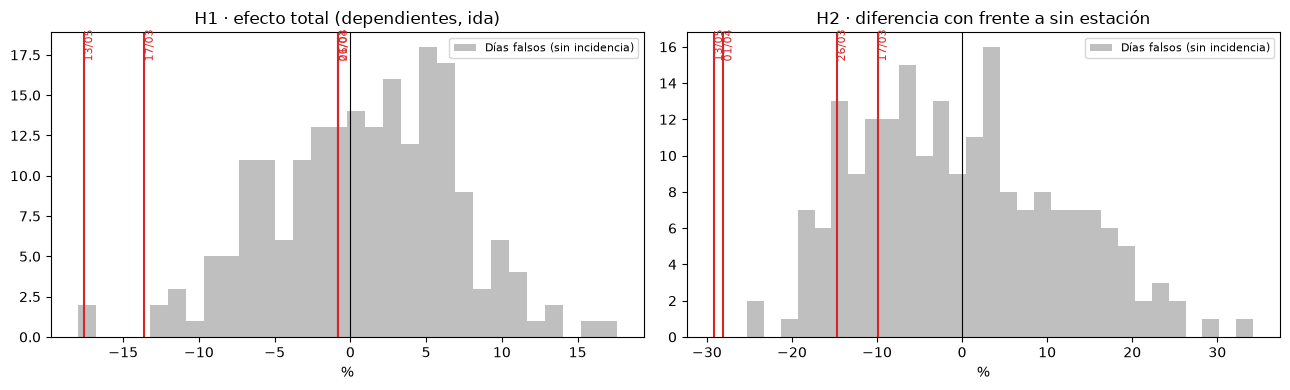

In [56]:
import contextlib, io
N_PLAC = 200
dep = info.index[info.dependiente]
ctrl = info.index[~info.rodalies]

# Panel municipio × tipo de barrio (con/sin estación) × día, calculado una sola vez (mismos filtros que regresion_h2)
P_EST = (m3.assign(est=m3.barrio_destino.map(barrios.con_estacion).map({True: "con", False: "sin"}))
           .groupby(["municipio_origen", "est", "fecha"], as_index=False).viajes.sum())
P_EST = P_EST[P_EST.fecha.isin(lim.union(caos_real))]
media_est = P_EST[P_EST.fecha.isin(lim)].groupby(["municipio_origen", "est"]).viajes.mean()
P_EST = P_EST[pd.MultiIndex.from_frame(P_EST[["municipio_origen", "est"]]).isin(media_est[media_est >= 200].index)]
P_EST = P_EST[P_EST.municipio_origen.isin(set(dep) | set(ctrl))].copy()
P_EST["y"] = np.log(P_EST.viajes)
P_EST["u_dow"] = P_EST.municipio_origen + "_" + P_EST.est + "_" + P_EST.fecha.dt.day_of_week.astype(str)

def h2_diferencia(dias):
    """Diferencia (con frente a sin estación) de los dependientes, en %, como en regresion_h2."""
    p = P_EST[P_EST.fecha.isin(lim.union(dias))].copy()
    caos = p.fecha.isin(dias) & p.municipio_origen.isin(dep)
    p["trat"], p["trat_con"] = caos.astype(int), (caos & (p.est == "con")).astype(int)
    m = pf.feols("y ~ trat + trat_con | u_dow + fecha:est", data=p, vcov={"CRV1": "municipio_origen"})
    return (np.exp(m.coef()["trat_con"]) - 1) * 100

def h1_total(dias):
    with contextlib.redirect_stdout(io.StringIO()):
        return regresion(p_mun, dep, pd.DatetimeIndex(dias))[0]

# Días de caos reales
real = pd.DataFrame({f"{d:%d/%m/%Y}": {"H1 total %": h1_total([d]), "H2 diferencia %": h2_diferencia([d])}
                     for d in caos_real}).T

# Días falsos (días limpios al azar con datos en M3)
lim_m3 = lim[lim.isin(p_mun.fecha.unique())]
rng = np.random.default_rng(0)
falsos = rng.choice(lim_m3, N_PLAC, replace=False)
plac = pd.DataFrame([{"H1 total %": h1_total([d]), "H2 diferencia %": h2_diferencia([d])}
                     for d in pd.DatetimeIndex(falsos)])

# p-valores (un día) y media de los 4 días frente a medias de 4 días falsos
for col in plac.columns:
    real[f"p {col.split()[0]}"] = [((plac[col] <= v).sum() + 1) / (N_PLAC + 1) for v in real[col]]
sims = {col: rng.choice(plac[col].values, (20000, len(caos_real))).mean(axis=1) for col in plac.columns}
real.loc["Media de los días de caos"] = [real["H1 total %"].mean(), real["H2 diferencia %"].mean(),
                                         ((sims["H1 total %"] <= real["H1 total %"].mean()).sum() + 1) / 20001,
                                         ((sims["H2 diferencia %"] <= real["H2 diferencia %"].mean()).sum() + 1) / 20001]

print("Días falsos: percentiles 2,5 y 97,5")
display(plac.quantile([.025, .5, .975]).round(1))
display(real.round({"H1 total %": 1, "H2 diferencia %": 1, "p H1": 3, "p H2": 3}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, tit in zip(axes, plac.columns, ["H1 · efecto total (dependientes, ida)",
                                             "H2 · diferencia con frente a sin estación"]):
    ax.hist(plac[col], bins=30, color="0.75", label="Días falsos (sin incidencia)")
    for f, v in real[col].drop("Media de los días de caos").items():
        ax.axvline(v, color="C3", lw=1.5); ax.text(v, ax.get_ylim()[1] * .9, f" {f[:5]}", color="C3", fontsize=8, rotation=90)
    ax.axvline(0, color="black", lw=.8); ax.set_title(tit); ax.set_xlabel("%"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Resultado.** *(Completar con las cifras de la tabla.)* Con días falsos, los dos efectos se reparten alrededor de 0. Los días de caos con un efecto claro en las secciones 1 y 2 (avería del 13/05 y huelga del 17/03) deberían quedar fuera de esa distribución. Si es así, los resultados de M3 no son casualidad.

### 6.2 ¿Coinciden los dos métodos?

Para cada día de caos y cada grupo, efecto total con el **clustering** (tipos de día de M2, corregido por el control) y con la **regresión**, a la ida y a la vuelta.

In [57]:
filas = []
dias_caso = {**{f"{d:%d/%m/%Y}": pd.DatetimeIndex([d]) for d in caos_real}, "Todos": pd.DatetimeIndex(caos_real)}
for sentido, panel in [("ida", p_mun), ("vuelta", p_mun_v)]:
    for etiqueta, dias in dias_caso.items():
        t = comparar_m3(panel, grupos, dias)
        for g, f in t.iterrows():
            filas.append({"sentido": sentido, "fecha": etiqueta, "grupo": g,
                          "clustering_%": f["clustering_%"], "clustering_p": f["clustering_p"],
                          "regresión_%": f["regresión_%"], "regresión_p": f["regresión_p"]})
conc = pd.DataFrame(filas).set_index(["sentido", "grupo", "fecha"]).sort_index()
display(conc)

x = conc.drop(index="Todos", level="fecha").astype(float)
print("Correlación clustering – regresión (por día, grupo y sentido):",
      round(x["clustering_%"].corr(x["regresión_%"]), 2))

clustering_%  \
sentido grupo                                      fecha                      
ida     Con alternativa (cercanos o con metro/FGC) 01/04/2025          -4.0   
                                                   13/05/2024           2.0   
                                                   17/03/2025           0.3   
                                                   26/03/2025          -4.3   
                                                   Todos               -1.5   
        Dependientes                               01/04/2025          -9.0   
                                                   13/05/2024         -14.7   
                                                   17/03/2025         -12.6   
                                                   26/03/2025           2.1   
                                                   Todos               -8.8   
vuelta  Con alternativa (cercanos o con metro/FGC) 01/04/2025          -3.0   
                                                   13/05/2024           2.2   
                                                   17/03/2025          -1.1   
                                                   26/03/2025          -5.5   
                                                   Todos               -1.9   
        Dependientes                               01/04/2025          -3.7   
                                                   13/05/2024         -11.5   
                                                   17/03/2025          -6.3   
                                                   26/03/2025          -0.5   
                                                   Todos               -5.6   

                                                               clustering_p  \
sentido grupo                                      fecha                      
ida     Con alternativa (cercanos o con metro/FGC) 01/04/2025         0.011   
                                                   13/05/2024         0.859   
                                                   17/03/2025         0.561   
                                                   26/03/2025         0.011   
                                                   Todos              0.040   
        Dependientes                               01/04/2025         0.023   
                                                   13/05/2024         0.008   
                                                   17/03/2025         0.011   
                                                   26/03/2025         0.687   
                                                   Todos              0.000   
vuelta  Con alternativa (cercanos o con metro/FGC) 01/04/2025         0.069   
                                                   13/05/2024         0.851   
                                                   17/03/2025         0.305   
                                                   26/03/2025         0.004   
                                                   Todos              0.027   
        Dependientes                               01/04/2025         0.156   
                                                   13/05/2024         0.008   
                                                   17/03/2025         0.038   
                                                   26/03/2025         0.481   
                                                   Todos              0.002   

                                                               regresión_%  \
sentido grupo                                      fecha                     
ida     Con alternativa (cercanos o con metro/FGC) 01/04/2025          4.3   
                                                   13/05/2024         -1.1   
                                                   17/03/2025          0.6   
                                                   26/03/2025         -5.3   
                                                   Todos              -0.4   
        Dependientes                   

Correlación clustering – regresión (por día, grupo y sentido): 0.79


**Resultado.** *(Completar con las cifras de la tabla.)* Si los dos métodos dan la misma dirección y una significancia parecida en los dependientes, y ≈ 0 en los municipios con alternativa, el resultado no depende del método.

## 7. Conclusiones

1. **M3 confirma M2.** Sumando todos los barrios, los dependientes caen en los días de caos y los municipios con alternativa no cambian. Las magnitudes de M3 son mayores y no se comparan con las de M2.
2. **La caída está en las estaciones.** Los viajes de los dependientes hacia los barrios con estación de Rodalies caen ≈ −19 % en los días de caos (≈ −27 % en la avería de la R1); hacia el resto de barrios, ≈ 0. La vuelta da lo mismo. Es la prueba más directa de que la caída se debe al tren.
3. **Sants es el punto más sensible:** −82 % de los viajes de los dependientes de la R1 el día de la avería.
4. **En las huelgas anunciadas la gente se adapta:** el total no cambia, pero los viajes se desplazan de los barrios con estación a los barrios sin estación. M2 no lo puede ver.
5. **Solo se notan los cortes de todo el día:** con datos diarios, los cortes de unas horas, los retrasos y las reducciones moderadas no cambian el volumen.
6. **Limitaciones:** las magnitudes dependen de la composición de los pares municipio–barrio; no se puede separar el efecto por línea; algunos placebos al límite (R1 el 19/02/2024) y días sin control limpio (30/04/2025, Montcada día 2). Ver B.3.

---
# B. Anexo técnico

### B.1 Métodos

**Regresión (H1, total por municipio).** Igual que en M2:

$$\log(\text{viajes}_{m,t}) = \alpha_{m,\,d(t)} + \delta_t + \beta \cdot \text{tratado}_{m,t} + \varepsilon_{m,t}$$

con efecto fijo municipio × día de la semana, efecto fijo de fecha y errores agrupados por municipio. Control = municipios sin Rodalies. Efecto % = $(e^{\beta} - 1) \times 100$.

**Regresión H2 (con/sin estación).** Para cada municipio se suman los viajes hacia barrios con y sin estación ($b \in \{\text{con}, \text{sin}\}$):

$$\log(\text{viajes}_{m,b,t}) = \alpha_{m,b,d(t)} + \delta_{t,b} + \beta_{\text{sin}} \cdot \text{tratado}_{m,t} + \gamma \cdot \text{tratado}_{m,t} \cdot \mathbb{1}[b = \text{con}] + \varepsilon$$

El efecto fijo fecha × tipo de barrio ($\delta_{t,b}$) descuenta lo que le pasa a todo el mundo ese día en cada tipo de barrio. $\gamma$ es la **diferencia** entre barrios con y sin estación. Solo se incluyen los pares municipio × tipo de barrio con ≥ 200 viajes/día.

**Barrio a barrio (H3).** Para cada barrio: log de los viajes de los afectados y del control, menos su media en los días limpios del mismo día de la semana; el efecto es la diferencia afectados − control el día de caos, y el z, ese efecto dividido por su desviación típica en los días limpios.

**Clustering.** Mismos tipos de día que en M2 (K-means por año sobre el volumen de los municipios sin Rodalies y la época del año, 4 tipos; ver el anexo B.1 del notebook 04). Efecto = (viajes del grupo / su mediana en los días limpios del mismo tipo) ÷ (lo mismo para el control) − 1. p: posición del efecto entre los días limpios (cada uno comparado con los demás días limpios de su tipo). *A diferencia de M2, aquí no se reentrena el clustering para cada placebo, porque los tipos vienen exportados.*

### B.2 Decisiones sobre los datos

- **Las filas repetidas no son duplicados.** En M3 una misma clave (día, segmento, municipio, barrio) puede tener de 1 a 10 filas con valores distintos, más en los municipios grandes (Badalona hasta 9, Sabadell 7). Hipótesis: Telefónica divide los municipios grandes en **subzonas**. Con la suma, M3 ≈ 84–87 % de M2 (razonable); con el máximo, ≈ 45 %. **Decisión: sumar.** *Pendiente de confirmar con el mentor de Telefónica.*
- **Ceros por privacidad:** los viajes < 15 se publican como 0. Una vez sumado, ≈ el 69 % de las combinaciones municipio × barrio × día son 0.
- **Ida y vuelta** tienen prácticamente el mismo volumen (≈ 1,00 ×).

### B.3 Limitaciones

- Las magnitudes de M3 no son comparables con las de M2 (composición de los pares municipio–barrio).
- No se puede separar el efecto por línea: casi todos los barrios con estación tienen varias líneas.
- El ranking de los 73 barrios uno por uno no es fiable (volúmenes pequeños y muchos tests).
- Placebo R1 del 19/02/2024 al límite (−15 % hacia barrios sin estación, p ≈ 0,05) sin explicación.
- Días sin control limpio: 30/04/2025 (después del apagón) y Montcada día 2.
- Verificar con un plano de 2024 la R7 y la R2S en Estació de França.

### B.4 Datos de turismo

Los ficheros de visitantes (por ejemplo, regionales por barrio y municipio de residencia) son **mensuales** y cuentan **visitantes únicos**: no sirven para medir el impacto de un día de incidencia. Como mucho, aportan contexto descriptivo.